# Unemployment Analysis with Python

## Oasis Infobyte — Data Science Internship

### Objective
Analyze unemployment trends across Indian states and regions,
with a focus on changes during the COVID-19 pandemic.

### Tools Used
- Python
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_theme(style="whitegrid")

In [6]:
df = pd.read_csv("C:/Users/tayyi/Downloads/Unemployment in India.csv")

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [8]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 768
Number of columns: 7
Dataset shape: (768, 7)


In [14]:
print("Column names:")
print(df.columns.tolist())

print("Data types:")
print(df.dtypes)

Column names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']
Data types:
Region                                      object
Date                                        object
Frequency                                   object
Estimated Unemployment Rate (%)            float64
Estimated Employed                         float64
Estimated Labour Participation Rate (%)    float64
Area                                        object
dtype: object


In [12]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64


In [16]:
print("Number of duplicate rows:", df.duplicated().sum())
df.describe(include="all")

Number of duplicate rows: 27


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
count,740,740,740,740.000000,7.400000e+02,740.000000,740
unique,28,14,2,NaN,NaN,NaN,2
top,Andhra Pradesh,31-10-2019,Monthly,NaN,NaN,NaN,Urban
freq,28,55,381,NaN,NaN,NaN,381
mean,NaN,NaN,NaN,11.787946,7.204460e+06,42.630122,NaN
std,NaN,NaN,NaN,10.721298,8.087988e+06,8.111094,NaN
min,NaN,NaN,NaN,0.000000,4.942000e+04,13.330000,NaN
25%,NaN,NaN,NaN,4.657500,1.190404e+06,38.062500,NaN
50%,NaN,NaN,NaN,8.350000,4.744178e+06,41.160000,NaN
75%,NaN,NaN,NaN,15.887500,1.127549e+07,45.505000,NaN


Step 2: Clean the dataset

In [19]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Check the new dataset size
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Remaining duplicate rows:", df_clean.duplicated().sum())

Original dataset shape: (768, 7)
Cleaned dataset shape: (741, 7)
Remaining duplicate rows: 0


In [21]:
# Check missing values in the cleaned dataset
print(df_clean.isnull().sum())

Region                                     1
Date                                       1
Frequency                                  1
Estimated Unemployment Rate (%)            1
Estimated Employed                         1
Estimated Labour Participation Rate (%)    1
Area                                       1
dtype: int64


In [23]:
# Convert Date into datetime format
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    dayfirst=True,
    errors="coerce"
)

# Remove extra spaces from text columns
df_clean["Region"] = df_clean["Region"].str.strip()
df_clean["Frequency"] = df_clean["Frequency"].str.strip()
df_clean["Area"] = df_clean["Area"].str.strip()

# Check the date conversion
print(df_clean["Date"].dtype)
print("Earliest date:", df_clean["Date"].min())
print("Latest date:", df_clean["Date"].max())

datetime64[ns]
Earliest date: 2019-05-31 00:00:00
Latest date: 2020-06-30 00:00:00


In [25]:
# Display the first five rows
display(df_clean.head())

# Check column types and missing values
df_clean.info()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


<class 'pandas.core.frame.DataFrame'>
Index: 741 entries, 0 to 753
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   740 non-null    object        
 1   Date                                     740 non-null    datetime64[ns]
 2   Frequency                                740 non-null    object        
 3   Estimated Unemployment Rate (%)          740 non-null    float64       
 4   Estimated Employed                       740 non-null    float64       
 5   Estimated Labour Participation Rate (%)  740 non-null    float64       
 6   Area                                     740 non-null    object        
dtypes: datetime64[ns](1), float64(3), object(3)
memory usage: 46.3+ KB


The dataset contains unemployment information for different regions of India, including estimated unemployment rates, employment figures, and labour force participation rates.
Duplicate rows were identified and removed to avoid counting identical records more than once.
The date column was converted to datetime format to support time-based analysis.

In [28]:
# Display rows containing missing values
display(df_clean[df_clean.isnull().any(axis=1)])

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
359,NaN,NaT,NaN,NaN,NaN,NaN,NaN


In [30]:
# Remove rows with missing values
df_clean = df_clean.dropna().reset_index(drop=True)

# Verify the cleaned dataset
print("Dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

Dataset shape: (740, 7)
Missing values: 0
Duplicate rows: 0


In [32]:
# Calculate average unemployment rate for each region
region_avg = (
    df_clean.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

display(region_avg)

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64

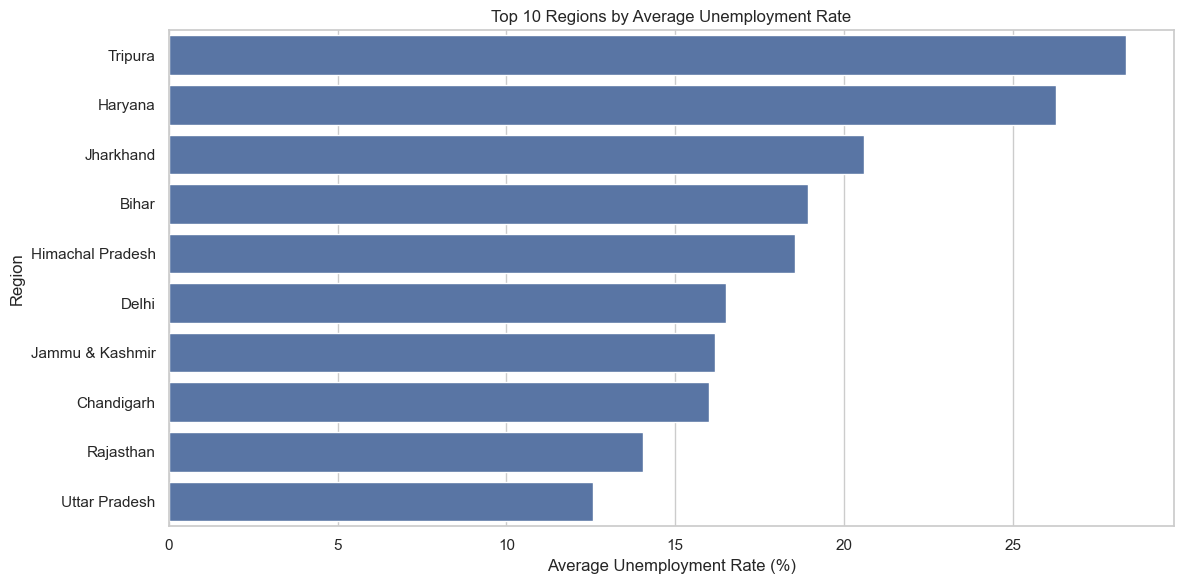

In [34]:
# Select the 10 regions with the highest average unemployment
top_10 = region_avg.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_10.values, y=top_10.index)

plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

This chart compares average unemployment rates across regions. The regions at the top have the highest average rates in this dataset. These averages describe the observed data period and do not necessarily represent current unemployment rates.

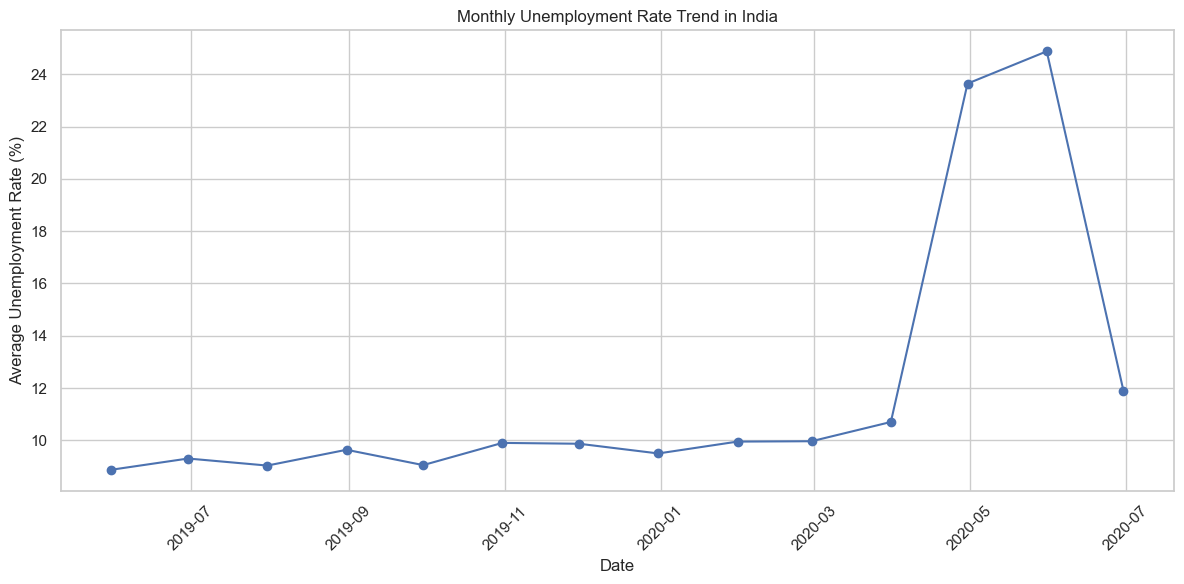

In [37]:
# Group the data by month
monthly_avg = (
    df_clean.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_index()
)

plt.figure(figsize=(12, 6))
plt.plot(monthly_avg.index, monthly_avg.values, marker="o")

plt.title("Monthly Unemployment Rate Trend in India")
plt.xlabel("Date")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Selected regions: ['Tripura', 'Haryana', 'Jharkhand']


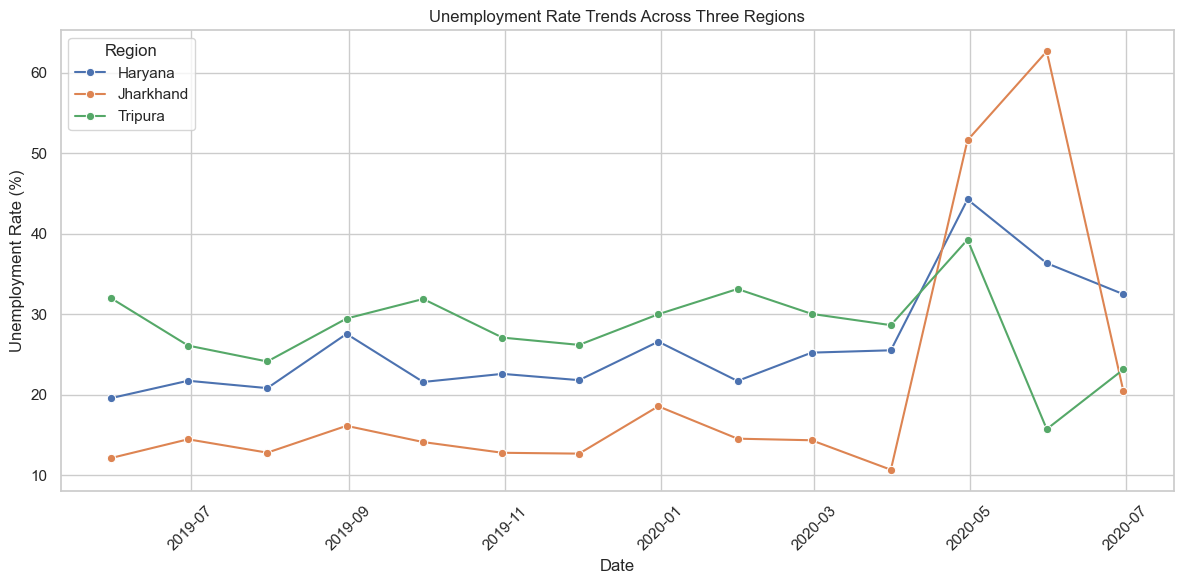

In [46]:
# Get the three regions with the highest average unemployment
selected_regions = region_avg.head(3).index.tolist()

print("Selected regions:", selected_regions)

# Filter the dataset
region_data = df_clean[df_clean["Region"].isin(selected_regions)]

# Plot unemployment trends
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=region_data,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    hue="Region",
    marker="o",
    errorbar=None
)

plt.title("Unemployment Rate Trends Across Three Regions")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="Region")
plt.tight_layout()
plt.show()

The line chart compares unemployment rate changes over time for three regions. Differences in the height and movement of the lines indicate how unemployment varied across regions during the study period. Peaks may reflect periods of increased unemployment, while declines indicate reductions in the measured rate.

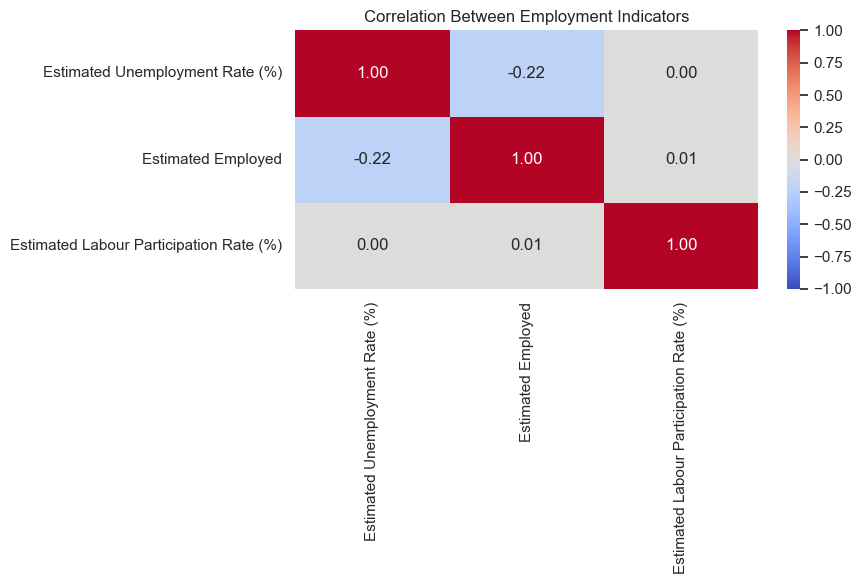

In [50]:
# Select the numerical columns for correlation analysis
numeric_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

correlation = df_clean[numeric_cols].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Employment Indicators")
plt.tight_layout()
plt.show()

In [52]:
# Make sure Date is in datetime format
df_clean["Date"] = pd.to_datetime(df_clean["Date"], errors="coerce")

# Create the Period column
df_clean["Period"] = df_clean["Date"].apply(
    lambda date: "Pre-COVID"
    if date < pd.Timestamp("2020-03-01")
    else "COVID Period"
)

# Verify that the column was created
print(df_clean[["Date", "Period"]].head())
print(df_clean["Period"].value_counts())

        Date     Period
0 2019-05-31  Pre-COVID
1 2019-06-30  Pre-COVID
2 2019-07-31  Pre-COVID
3 2019-08-31  Pre-COVID
4 2019-09-30  Pre-COVID
Period
Pre-COVID       536
COVID Period    204
Name: count, dtype: int64


In [54]:
period_avg = (
    df_clean.groupby("Period")["Estimated Unemployment Rate (%)"]
    .mean()
    .reindex(["Pre-COVID", "COVID Period"])
)

display(period_avg.to_frame("Average Unemployment Rate (%)"))

,Average Unemployment Rate (%)
Period,
Pre-COVID,9.509534
COVID Period,17.774363


In [56]:
pre_covid = period_avg["Pre-COVID"]
covid_period = period_avg["COVID Period"]

difference = covid_period - pre_covid

print(f"Pre-COVID average: {pre_covid:.2f}%")
print(f"COVID-period average: {covid_period:.2f}%")
print(f"Difference: {difference:+.2f} percentage points")

Pre-COVID average: 9.51%
COVID-period average: 17.77%
Difference: +8.26 percentage points


In [58]:
print(df_clean.columns.tolist())

['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area', 'Period']


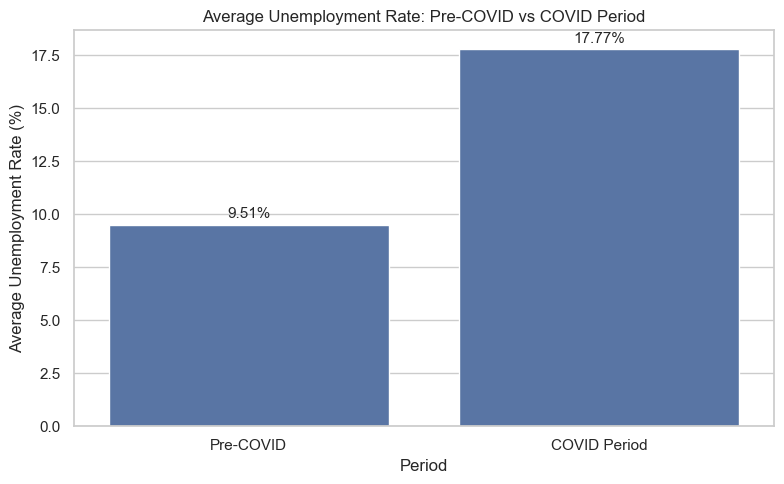

In [78]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=period_avg.index,
    y=period_avg.values
)

# Display the exact percentage above each bar
for i, value in enumerate(period_avg.values):
    ax.text(i, value + 0.3, f"{value:.2f}%", 
            ha="center", fontsize=11)

plt.title("Average Unemployment Rate: Pre-COVID vs COVID Period")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

### Observation: Pre-COVID vs COVID Period

The bar chart shows that the average unemployment rate increased from **9.51% in the pre-COVID period** to **17.77% during the COVID period**. This represents an increase of **8.26 percentage points**. The result suggests that unemployment was considerably higher during the period beginning in March 2020. However, this comparison alone does not prove that COVID-19 was the only cause of the increase.

## Conclusion

This project analyzed unemployment trends in India using Python, Pandas, Matplotlib, and Seaborn. The dataset was inspected and cleaned by checking missing values and removing duplicate records.

Exploratory data analysis was performed to examine regional unemployment averages, monthly trends, differences across regions, and correlations between unemployment rate, estimated employment, and labour force participation rate.

The comparison between the pre-COVID and COVID periods showed that the average unemployment rate increased from **9.51% to 17.77%**, a difference of **8.26 percentage points**. This indicates higher unemployment in the dataset during the period beginning in March 2020, although the analysis does not prove that COVID-19 alone caused the increase.

Overall, this project demonstrates how data analysis and visualization can help identify patterns and changes in unemployment over time.